# Random Forest: muchos árboles para priorizar hogares

Este cuaderno contiene un análisis del modelo Random Forest. El modelo describe asociaciones predictivas. No permite concluir que una característica cause pobreza.

**Datos.** `datos.xlsx` Este cuaderno reproduce el análisis del script `modelo_random_forest.py`, paso a paso y con explicaciones. La clase positiva es **Sí**. Ejecute las celdas en orden desde esta carpeta. El conjunto de prueba se reserva para la evaluación final; el ajuste de parámetros y del umbral usa validación cruzada y predicciones OOB del entrenamiento.

## Preparación e importaciones


In [1]:
"""Análisis didáctico de clasificación de pobreza con Random Forest."""

# Primero se comprueba e instala, si hace falta, cada dependencia solicitada.
import importlib.util
import sys
import subprocess

dependencias = {
    "pandas": "pandas",
    "numpy": "numpy",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "openpyxl": "openpyxl",
}
faltantes = [paquete for modulo, paquete in dependencias.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    print("Instalando dependencias faltantes:", ", ".join(faltantes))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *faltantes])

# Los imports de las librerías se hacen después de la comprobación.
from pathlib import Path
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, fbeta_score)
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier


## 1. Rutas, lectura y descripción inicial

Leemos la hoja hogares, comprobamos que estén las columnas pedidas y revisamos valores ausentes. “Sí” se reconoce aunque el archivo use acentos con una codificación distinta. Al final de la celda se muestra el tamaño de la base, el porcentaje positivo y cuántos registros completos usaremos.

In [2]:
RUTA_PROYECTO = Path.cwd()
if not (RUTA_PROYECTO / "datos" / "2-2-hogares-subsidio.xlsx").exists() and (RUTA_PROYECTO / "4. Random Forest" / "datos" / "2-2-hogares-subsidio.xlsx").exists():
    RUTA_PROYECTO = RUTA_PROYECTO / "4. Random Forest"
RUTA_DATOS = RUTA_PROYECTO / "datos" / "2-2-hogares-subsidio.xlsx"
RUTA_RESULTADOS = RUTA_PROYECTO / "resultados"
RUTA_FIGURAS = RUTA_PROYECTO / "visualizaciones"
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)
RUTA_EXCEL = RUTA_RESULTADOS / "random_forest_resultados.xlsx"
RANDOM_STATE = 42

print("PASO 1: Leyendo datos y revisando calidad")
if not RUTA_DATOS.exists():
    raise FileNotFoundError(f"No se encontró el archivo de entrada: {RUTA_DATOS}")
datos = pd.read_excel(RUTA_DATOS, sheet_name="hogares", engine="openpyxl")
columnas_x = ["ingreso_pc", "educacion_jefe", "hacinamiento", "menores_5",
              "acueducto", "piso_tierra", "internet", "zona", "regimen_salud"]
columna_y = "pobre"
requeridas = columnas_x + [columna_y]
faltan_columnas = [c for c in requeridas if c not in datos.columns]
if faltan_columnas:
    raise ValueError(f"Faltan columnas requeridas: {faltan_columnas}")

filas, columnas = datos.shape
faltantes = datos[requeridas].isna().sum()

def normalizar_texto(valor):
    """Convierte texto a una forma comparable, sin acentos ni espacios sobrantes."""
    texto = str(valor).strip().lower()
    texto = unicodedata.normalize("NFKD", texto)
    return "".join(c for c in texto if not unicodedata.combining(c))

objetivo_normalizado = datos[columna_y].map(normalizar_texto)
positivos = objetivo_normalizado.isin(["si", "sí", "yes", "1", "true"])
negativos = objetivo_normalizado.isin(["no", "0", "false"])
if (~(positivos | negativos) & datos[columna_y].notna()).any():
    valores = datos.loc[~(positivos | negativos) & datos[columna_y].notna(), columna_y].unique()
    raise ValueError(f"Valores inesperados en 'pobre': {valores}")
porcentaje_si = positivos.mean() * 100
descripcion = pd.DataFrame({
    "indicador": ["filas", "columnas", "casos positivos (Sí)", "casos negativos (No)",
                  "porcentaje de casos Sí", "celdas faltantes en variables del modelo"],
    "valor": [filas, columnas, int(positivos.sum()), int(negativos.sum()),
              porcentaje_si, int(faltantes.sum())],
})
descripcion_faltantes = faltantes.rename_axis("variable").reset_index(name="faltantes")
descripcion = pd.concat([descripcion,
                         pd.DataFrame({"indicador": ["--- faltantes por variable ---"] * len(faltantes),
                                       "valor": [f"{r.variable}: {r.faltantes}" for r in descripcion_faltantes.itertuples()]})],
                        ignore_index=True)
print(f"  Filas: {filas:,}; columnas: {columnas}; porcentaje Sí: {porcentaje_si:.1f}%")
print(f"  Faltantes entre las variables usadas: {int(faltantes.sum())}")

# Se eliminan únicamente registros incompletos en variables de entrada o respuesta.
analisis = datos[requeridas].copy()
antes = len(analisis)
analisis = analisis.dropna(subset=requeridas).copy()
print(f"  Registros completos para el modelo: {len(analisis):,} (se excluyeron {antes-len(analisis)})")


PASO 1: Leyendo datos y revisando calidad
  Filas: 1,200; columnas: 17; porcentaje Sí: 32.8%
  Faltantes entre las variables usadas: 0
  Registros completos para el modelo: 1,200 (se excluyeron 0)


## 2. Codificación de la respuesta y de predictores categóricos

El modelo necesita números. Por eso la respuesta pobre se codifica como 1 para Sí y 0 para No. Las categorías de texto se convierten en columnas indicadoras (0/1), por ejemplo una columna para cada zona.

In [3]:
print("PASO 2: Convirtiendo la respuesta a 0/1 y preparando las variables X")
analisis["pobre_binaria"] = analisis[columna_y].map(
    lambda valor: int(normalizar_texto(valor) in ["si", "sí", "yes", "1", "true"]))
y = analisis["pobre_binaria"]
X_original = analisis[columnas_x].copy()
# One-hot crea una columna 0/1 para cada categoría de texto, por ejemplo zona_Rural.
X = pd.get_dummies(X_original, columns=["acueducto", "piso_tierra", "internet", "zona", "regimen_salud"],
                   drop_first=False, dtype=int)
X = X.apply(pd.to_numeric, errors="raise").astype(float)
print(f"  La clase positiva Sí vale 1; las variables del modelo quedan en {X.shape[1]} columnas.")


PASO 2: Convirtiendo la respuesta a 0/1 y preparando las variables X
  La clase positiva Sí vale 1; las variables del modelo quedan en 15 columnas.


## 3. Separación estratificada: 75% entrenamiento y 25% prueba

Separamos los registros antes de aprender. La estratificación mantiene aproximadamente el mismo porcentaje de hogares pobres en ambos grupos. El conjunto de prueba queda reservado para medir el desempeño final.

In [4]:
print("PASO 3: Separando entrenamiento y prueba de forma estratificada")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
print(f"  Entrenamiento: {len(X_train):,}; prueba: {len(X_test):,}.")
print(f"  Proporción Sí: entrenamiento {y_train.mean():.1%}; prueba {y_test.mean():.1%}.")

# Métricas comunes para comparar modelos y conjuntos.
def calcular_metricas(y_real, y_clase, y_prob):
    return {
        "accuracy": accuracy_score(y_real, y_clase),
        "precision": precision_score(y_real, y_clase, zero_division=0),
        "recall": recall_score(y_real, y_clase, zero_division=0),
        "auc": roc_auc_score(y_real, y_prob) if len(np.unique(y_real)) == 2 else np.nan,
    }

def predecir_probabilidad(modelo, matriz):
    """Toma la columna de probabilidad que corresponde a la clase positiva 1."""
    indice = list(modelo.classes_).index(1)
    return modelo.predict_proba(matriz)[:, indice]


PASO 3: Separando entrenamiento y prueba de forma estratificada
  Entrenamiento: 900; prueba: 300.
  Proporción Sí: entrenamiento 32.9%; prueba 32.7%.


## 4. Bosque inicial: bootstrap, max_features y votación

Cada árbol aprende una muestra bootstrap: una selección aleatoria con reemplazo de los datos de entrenamiento. En cada división, max_features limita las variables que el árbol puede considerar; esto hace que los árboles sean distintos. Finalmente, se promedian sus probabilidades o se vota por la clase. OOB estima el error usando, para cada hogar de entrenamiento, los árboles que no incluyeron ese hogar en su muestra bootstrap.

In [5]:
print("PASO 4: Ajustando un bosque inicial de 300 árboles con OOB")
print("  Bootstrap: cada árbol aprende con una muestra aleatoria con reemplazo.")
print("  max_features: limita cuántas variables candidatas mira cada división.")
print("  Votación: los árboles votan la clase; sus probabilidades se promedian.")
bosque_inicial = RandomForestClassifier(n_estimators=300, oob_score=True,
    random_state=RANDOM_STATE, n_jobs=1, class_weight=None)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    bosque_inicial.fit(X_train, y_train)
print(f"  Exactitud OOB inicial: {bosque_inicial.oob_score_:.3f}")


PASO 4: Ajustando un bosque inicial de 300 árboles con OOB
  Bootstrap: cada árbol aprende con una muestra aleatoria con reemplazo.
  max_features: limita cuántas variables candidatas mira cada división.
  Votación: los árboles votan la clase; sus probabilidades se promedian.
  Exactitud OOB inicial: 0.880


## 5. Error OOB frente al número de árboles

La figura 01 muestra el error OOB cuando añadimos árboles. Si la curva se estabiliza, más árboles aportan poco cambio y la estimación se vuelve más estable. La tabla oob contiene error, exactitud y AUC OOB para cada cantidad de árboles probada.

PASO 5: Calculando error OOB desde 10 hasta 400 árboles


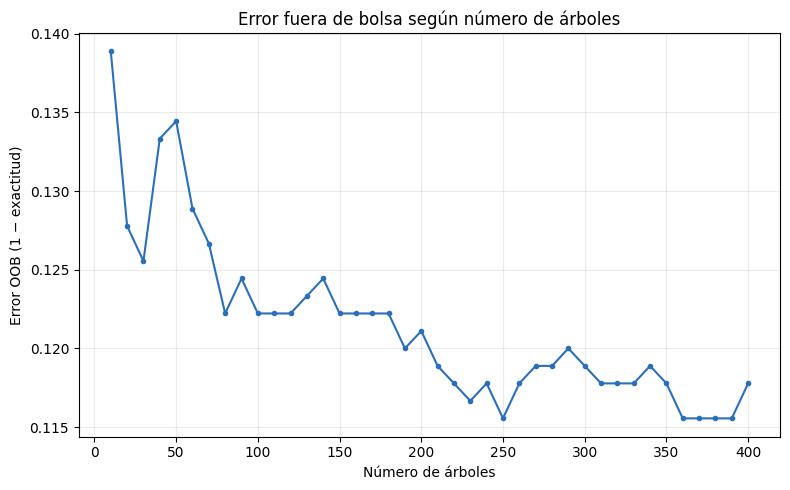

  Error OOB con 400 árboles: 0.118


In [6]:
print("PASO 5: Calculando error OOB desde 10 hasta 400 árboles")
oob_modelo = RandomForestClassifier(n_estimators=400, oob_score=True, warm_start=True,
    random_state=RANDOM_STATE, n_jobs=1, class_weight=None)
filas_oob = []
conteos = sorted(set(list(range(10, 401, 10)) + [400]))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for n_arboles in conteos:
        oob_modelo.set_params(n_estimators=n_arboles)
        oob_modelo.fit(X_train, y_train)
        prob_oob = oob_modelo.oob_decision_function_[:, 1]
        validas = np.isfinite(prob_oob)
        pred_oob = (prob_oob >= 0.5).astype(int)
        filas_oob.append({"arboles": n_arboles,
                          "error_oob": 1 - accuracy_score(y_train[validas], pred_oob[validas]),
                          "accuracy_oob": accuracy_score(y_train[validas], pred_oob[validas]),
                          "auc_oob": roc_auc_score(y_train[validas], prob_oob[validas])})
tabla_oob = pd.DataFrame(filas_oob)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tabla_oob["arboles"], tabla_oob["error_oob"], color="#2a6fbb", marker="o", ms=3)
ax.set(title="Error fuera de bolsa según número de árboles", xlabel="Número de árboles", ylabel="Error OOB (1 − exactitud)")
ax.grid(alpha=.25); fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "01_oob_arboles.png", dpi=150)
plt.show()
print(f"  Error OOB con 400 árboles: {tabla_oob.iloc[-1]['error_oob']:.3f}")


## 6. Selección de max_features y min_samples_leaf mediante validación cruzada

Probamos combinaciones de parámetros en cinco pliegues estratificados. AUC evalúa qué tan bien ordena el modelo hogares pobres por encima de no pobres a través de todos los umbrales. Se escogen los parámetros con mayor AUC medio. Para ahorrar tiempo, la búsqueda compara 100 árboles por combinación y después el modelo final se vuelve a ajustar con 300 árboles.

In [7]:
print("PASO 6: Buscando parámetros con 5 pliegues estratificados y AUC")
rejilla = {"max_features": ["sqrt", 0.5, 0.75], "min_samples_leaf": [1, 2, 5, 10]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
busqueda_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1),
    param_grid=rejilla, scoring="roc_auc", cv=cv, n_jobs=1, refit=True,
    return_train_score=True, verbose=0)
busqueda_rf.fit(X_train, y_train)
tabla_busqueda = pd.DataFrame(busqueda_rf.cv_results_)[[
    "param_max_features", "param_min_samples_leaf", "mean_test_score", "std_test_score",
    "mean_train_score", "rank_test_score"]].rename(columns={
        "param_max_features": "max_features", "param_min_samples_leaf": "min_samples_leaf",
        "mean_test_score": "auc_cv_media", "std_test_score": "auc_cv_desviacion",
        "mean_train_score": "auc_entrenamiento_media", "rank_test_score": "orden"})
mejores = busqueda_rf.best_params_
print(f"  Mejor combinación: {mejores}; AUC CV medio: {busqueda_rf.best_score_:.3f}")

# El bosque final usa los parámetros elegidos por CV y conserva estimación OOB.
bosque = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=RANDOM_STATE,
    n_jobs=1, **mejores)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    bosque.fit(X_train, y_train)
prob_train_rf = predecir_probabilidad(bosque, X_train)
prob_test_rf = predecir_probabilidad(bosque, X_test)
prob_oob_final = bosque.oob_decision_function_[:, 1]
oob_validas = np.isfinite(prob_oob_final)
pred_oob_rf = (prob_oob_final >= 0.5).astype(int)


PASO 6: Buscando parámetros con 5 pliegues estratificados y AUC
  Mejor combinación: {'max_features': 0.75, 'min_samples_leaf': 10}; AUC CV medio: 0.953


## 7. Matriz de confusión a umbral 0,5

La figura 02 compara la clase real y la clase predicha en los datos de prueba.

PASO 7: Dibujando matriz de confusión del bosque en prueba (umbral 0,5)


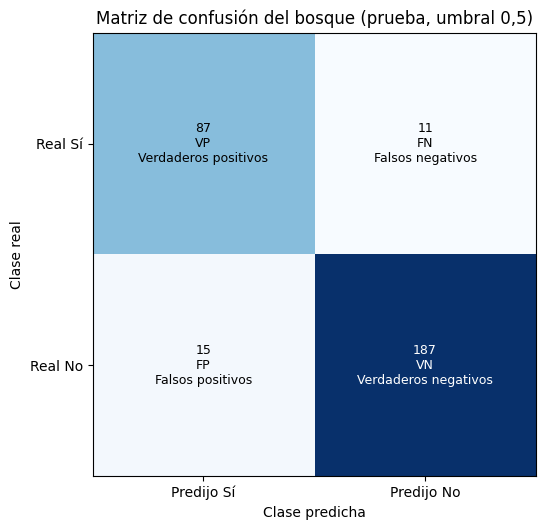

In [8]:
print("PASO 7: Dibujando matriz de confusión del bosque en prueba (umbral 0,5)")
pred_test_rf = (prob_test_rf >= 0.5).astype(int)
cm = confusion_matrix(y_test, pred_test_rf, labels=[1, 0])
fig, ax = plt.subplots(figsize=(6.5, 5.4))
ax.imshow(cm, interpolation="nearest", cmap="Blues")
ax.set_xticks([0, 1], labels=["Predijo Sí", "Predijo No"])
ax.set_yticks([0, 1], labels=["Real Sí", "Real No"])
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title("Matriz de confusión del bosque (prueba, umbral 0,5)")
rotulos = [["VP\nVerdaderos positivos", "FN\nFalsos negativos"],
           ["FP\nFalsos positivos", "VN\nVerdaderos negativos"]]
for (i, j), rotulo in np.ndenumerate(np.array(rotulos)):
    color = "white" if cm[i, j] > cm.max() * 0.55 else "black"
    ax.text(j, i, f"{cm[i, j]}\n{rotulo}", ha="center", va="center", fontsize=9, color=color)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "02_matriz_confusion.png", dpi=150)
plt.show()


## 8. Comparación de métricas: entrenamiento, OOB y prueba


In [9]:
print("PASO 8: Comparando bosque, línea base, árbol y regresión logística")
modelos = {
    "Línea base (clase más común)": DummyClassifier(strategy="most_frequent"),
    "Árbol de decisión": DecisionTreeClassifier(random_state=RANDOM_STATE, min_samples_leaf=mejores["min_samples_leaf"]),
    "Regresión logística": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
}
modelos["Random Forest"] = bosque
for nombre, modelo in modelos.items():
    if nombre != "Random Forest":
        modelo.fit(X_train, y_train)

filas_metricas = []
for nombre, modelo in modelos.items():
    for particion, xx, yy in [("entrenamiento", X_train, y_train), ("prueba", X_test, y_test)]:
        pp = predecir_probabilidad(modelo, xx)
        clase = (pp >= 0.5).astype(int)
        filas_metricas.append({"modelo": nombre, "particion": particion,
                               **calcular_metricas(yy, clase, pp)})
    if nombre == "Random Forest":
        filas_metricas.append({"modelo": nombre, "particion": "OOB",
                               **calcular_metricas(y_train[oob_validas], pred_oob_rf[oob_validas],
                                                   prob_oob_final[oob_validas])})
tabla_metricas = pd.DataFrame(filas_metricas)
display(tabla_metricas)


PASO 8: Comparando bosque, línea base, árbol y regresión logística


,modelo,particion,accuracy,precision,recall,auc
0,Línea base (clase más común),entrenamiento,0.671111,0.000000,0.000000,0.500000
1,Línea base (clase más común),prueba,0.673333,0.000000,0.000000,0.500000
2,Árbol de decisión,entrenamiento,0.921111,0.873754,0.888514,0.977540
3,Árbol de decisión,prueba,0.913333,0.867347,0.867347,0.949232
4,Regresión logística,entrenamiento,0.887778,0.837370,0.817568,0.947344
5,Regresión logística,prueba,0.866667,0.802083,0.785714,0.936906
6,Random Forest,entrenamiento,0.922222,0.869281,0.898649,0.980144
7,Random Forest,prueba,0.913333,0.852941,0.887755,0.956860
8,Random Forest,OOB,0.894444,0.836120,0.844595,0.954425


## 9. Curvas ROC, umbrales y recomendación


PASO 9: Graficando ROC y evaluando umbrales


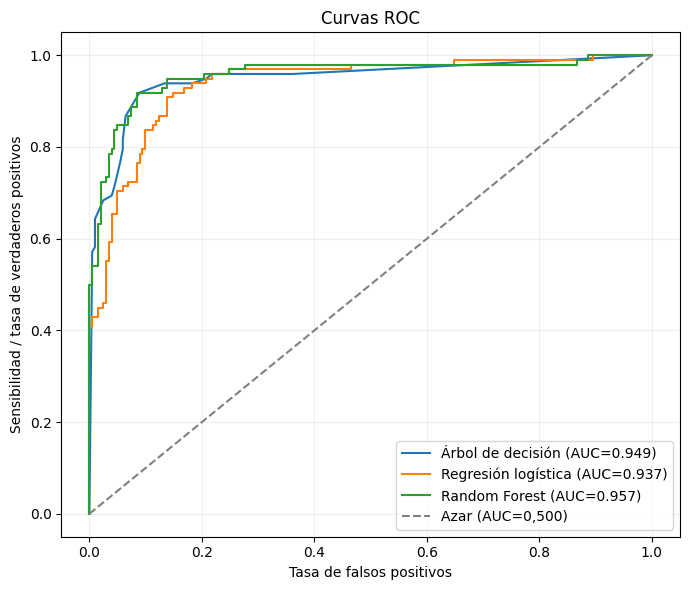

In [10]:
print("PASO 9: Graficando ROC y evaluando umbrales")
fig, ax = plt.subplots(figsize=(7, 6))
for nombre, modelo in modelos.items():
    if nombre == "Línea base (clase más común)":
        continue
    pp = predecir_probabilidad(modelo, X_test)
    fpr, tpr, _ = roc_curve(y_test, pp)
    auc = roc_auc_score(y_test, pp)
    ax.plot(fpr, tpr, label=f"{nombre} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC=0,500)")
ax.set(xlabel="Tasa de falsos positivos", ylabel="Sensibilidad / tasa de verdaderos positivos", title="Curvas ROC")
ax.legend(loc="lower right"); ax.grid(alpha=.2); fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "03_curva_roc.png", dpi=150)
plt.show()

umbrales = np.round(np.arange(0.1, 1.0, 0.1), 1)
filas_umbrales = []
for umbral in umbrales:
    clases = (prob_test_rf >= umbral).astype(int)
    m = calcular_metricas(y_test, clases, prob_test_rf)
    filas_umbrales.append({"umbral": umbral, **m,
                           "f2": fbeta_score(y_test, clases, beta=2, zero_division=0)})
tabla_umbrales = pd.DataFrame(filas_umbrales)
umbrales_oob = np.round(np.arange(0.1, 1.0, 0.1), 1)
f2_oob = [fbeta_score(y_train[oob_validas], (prob_oob_final[oob_validas] >= t).astype(int), beta=2, zero_division=0) for t in umbrales_oob]
umbral_recomendado = float(umbrales_oob[int(np.argmax(f2_oob))])


## 10. Importancias


PASO 10: Importancias


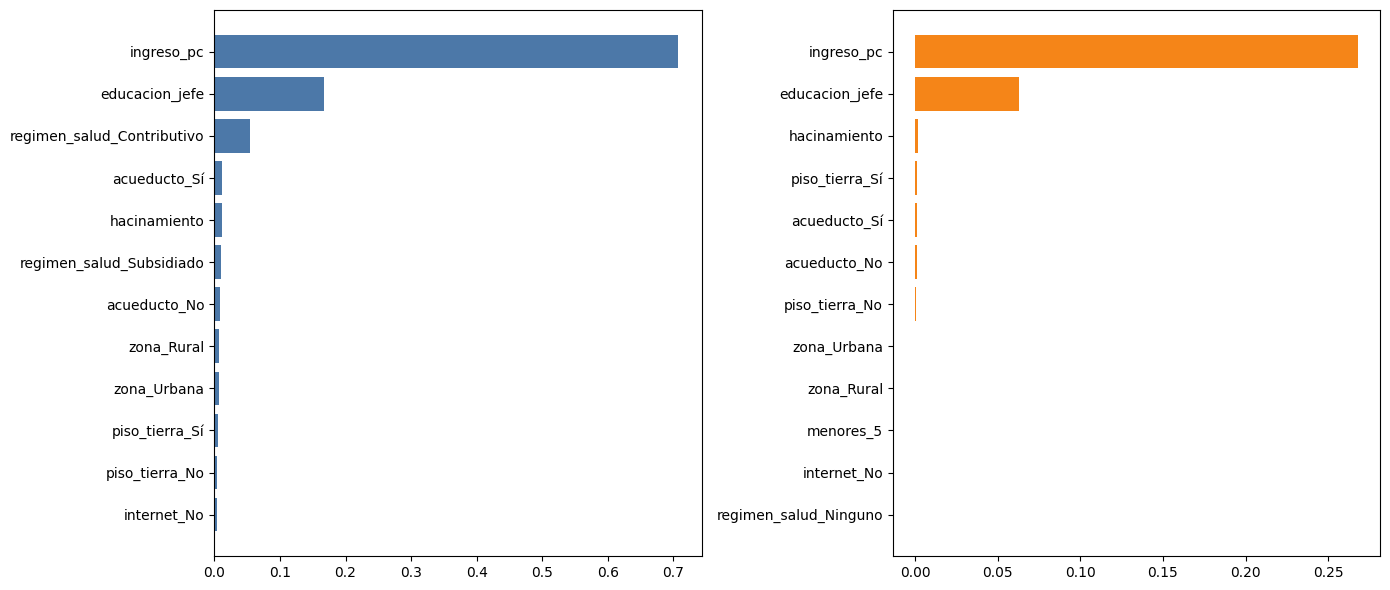

In [12]:
print("PASO 10: Importancias")
imp_impureza = pd.Series(bosque.feature_importances_, index=X.columns, name="importancia_impureza")
perm = permutation_importance(bosque, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=RANDOM_STATE, n_jobs=1)
imp_perm = pd.Series(perm.importances_mean, index=X.columns, name="importancia_permutacion_auc")
imp_perm_sd = pd.Series(perm.importances_std, index=X.columns, name="desviacion_permutacion")
tabla_importancia = pd.concat([imp_impureza, imp_perm, imp_perm_sd], axis=1).reset_index(names="variable")
tabla_importancia = tabla_importancia.sort_values("importancia_permutacion_auc", ascending=False)
fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
top_imp = imp_impureza.sort_values(ascending=True).tail(12)
top_perm = imp_perm.sort_values(ascending=True).tail(12)
ejes[0].barh(top_imp.index, top_imp.values, color="#4c78a8")
ejes[1].barh(top_perm.index, top_perm.values, color="#f58518")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "04_importancia.png", dpi=150)
plt.show()


## 11. Dependencia Parcial


PASO 11: Graficando dependencia parcial de las dos variables principales
  Variables seleccionadas para dependencia parcial: ['ingreso_pc', 'educacion_jefe']


<Figure size 640x480 with 0 Axes>

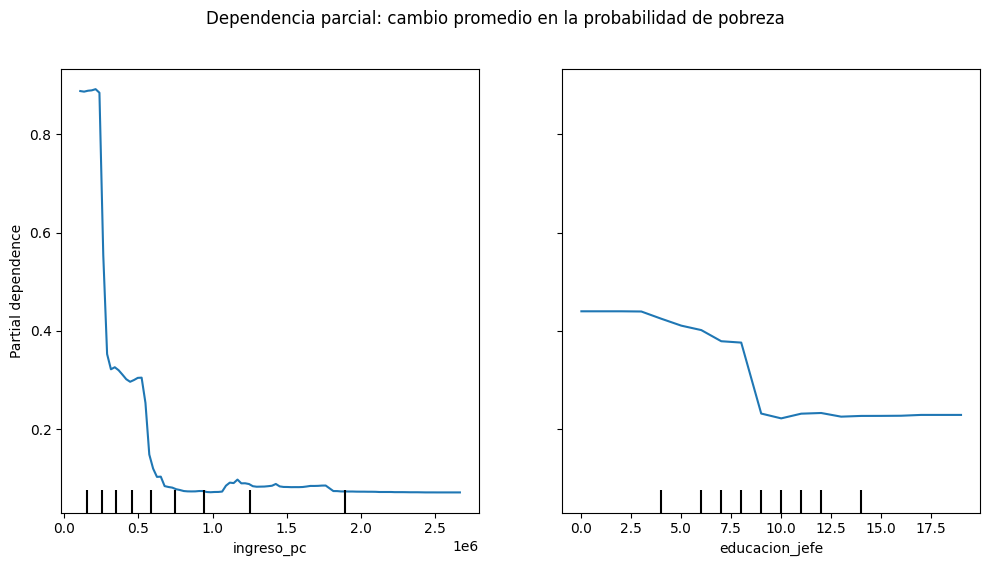

In [14]:
print("PASO 11: Graficando dependencia parcial de las dos variables principales")

# 1. Recuperación segura de las dos variables principales directamente desde el modelo
# Esto asegura que la celda funcione de forma independiente sin depender de 'imp_perm'
importances = bosque.feature_importances_
indices_top2 = np.argsort(importances)[-2:][::-1]
dos_mas = [X.columns[i] for i in indices_top2]

print(f"  Variables seleccionadas para dependencia parcial: {dos_mas}")

# 2. Inicialización limpia del entorno gráfico
plt.figure()

# 3. Llamada al estimador dejando que Scikit-Learn gestione el diseño de los subgráficos
display = PartialDependenceDisplay.from_estimator(
    bosque, 
    X_train, 
    features=dos_mas, 
    kind="average", 
    n_jobs=1
)

# 4. Recuperación de la figura generada automáticamente por Scikit-Learn
fig = display.figure_
fig.set_size_inches(10, 5.5)
fig.suptitle("Dependencia parcial: cambio promedio en la probabilidad de pobreza", fontsize=12, y=1.02)
fig.tight_layout()

# 5. Guardado y renderizado inline definitivo
fig.savefig(RUTA_FIGURAS / "05_dependencia_parcial.png", dpi=150, bbox_inches='tight')
plt.show()



## 12. Exportación a Excel


In [ ]:
print("PASO 12: Guardando Excel")
predicciones = pd.DataFrame({
    "indice_original": X_test.index,
    "real": np.where(y_test.to_numpy() == 1, "Sí", "No"),
    "probabilidad_Si": prob_test_rf,
    "clase_predicha_umbral_0_5": np.where(pred_test_rf == 1, "Sí", "No"),
    "clase_predicha_umbral_recomendado": np.where(prob_test_rf >= umbral_recomendado, "Sí", "No"),
}).sort_values("indice_original")

resumen = pd.DataFrame([("Registros analizados", len(analisis))], columns=["indicador", "valor"])
with pd.ExcelWriter(RUTA_EXCEL, engine="openpyxl") as escritor:
    hojas = {"resumen": resumen, "descripcion": descripcion, "oob": tabla_oob,
             "busqueda": tabla_busqueda, "metricas": tabla_metricas,
             "umbrales": tabla_umbrales, "importancia": tabla_importancia,
             "predicciones": predicciones}
    for nombre_hoja, tabla in hojas.items():
        tabla.to_excel(escritor, sheet_name=nombre_hoja, index=False)
print("Hecho")
